✅ Данные успешно загружены!
              страна  рождаем  смертн  деск_см  длит_муж  длит_жен  доход  \
0            Albania     24.7     5.7     30.8      69.6      75.5    600   
1           Bulgaria     12.5    11.9     14.4      68.3      74.7   2250   
2     Czechoslovakia     13.4    11.7     11.3      71.8      77.7   2980   
3  Former_E._Germany     12.0    12.4      7.6      69.8      75.9  -9999   
4            Hungary     11.6    13.4     14.8      65.4      73.8   2780   

   регион  
0       1  
1       1  
2       1  
3       1  
4       1  

✅ Размер после очистки: (30, 6)


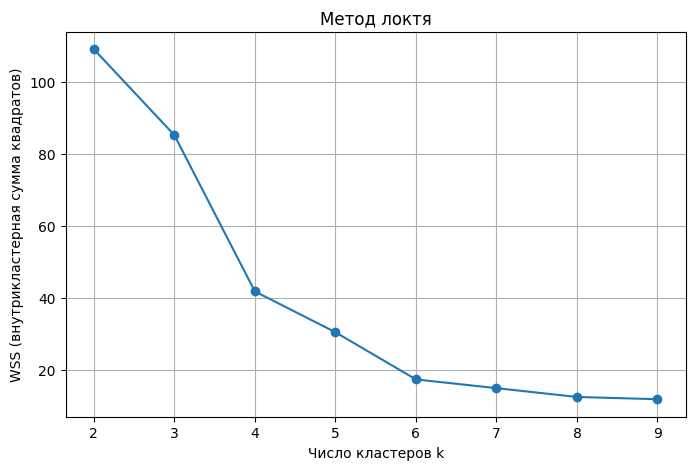

              Страна  Кластер  Регион
0            Albania        1       1
1           Bulgaria        2       1
2     Czechoslovakia        2       1
3  Former_E._Germany        2       1
4            Hungary        2       1
Таблица соответствия регионов и кластеров:
Кластер  0  1  2  3
Регион             
1        0  1  7  0
2        0  7  2  1
3        1  3  0  0
4        0  2  0  2
5        0  2  0  0
6        0  1  0  1
Adjusted Rand Index (ARI): 0.180
Normalized Mutual Information (NMI): 0.369


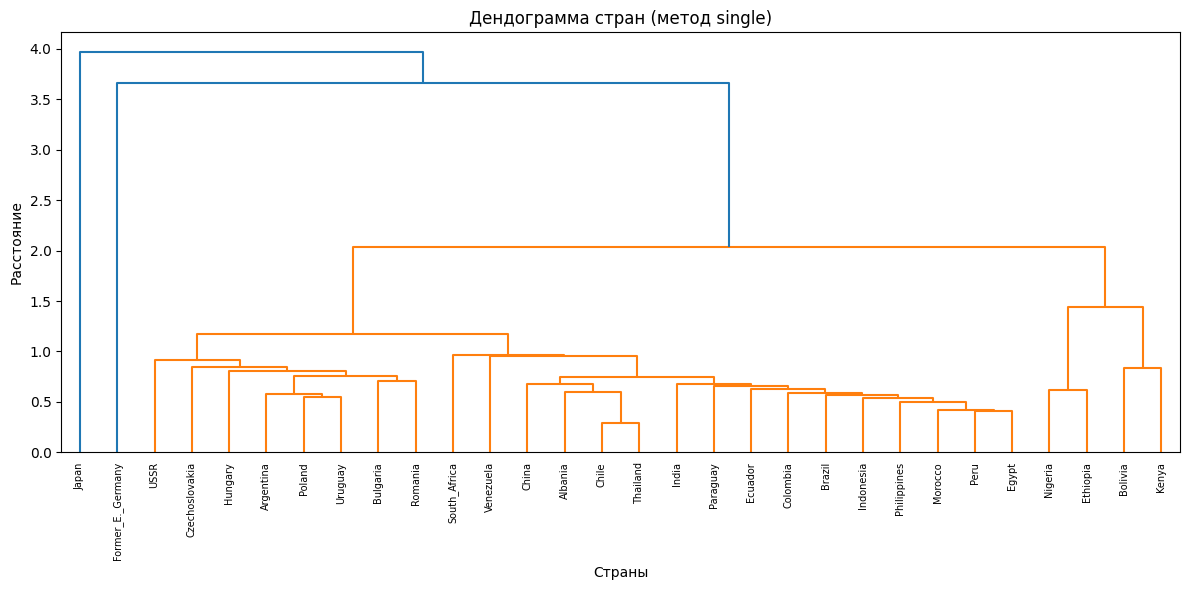

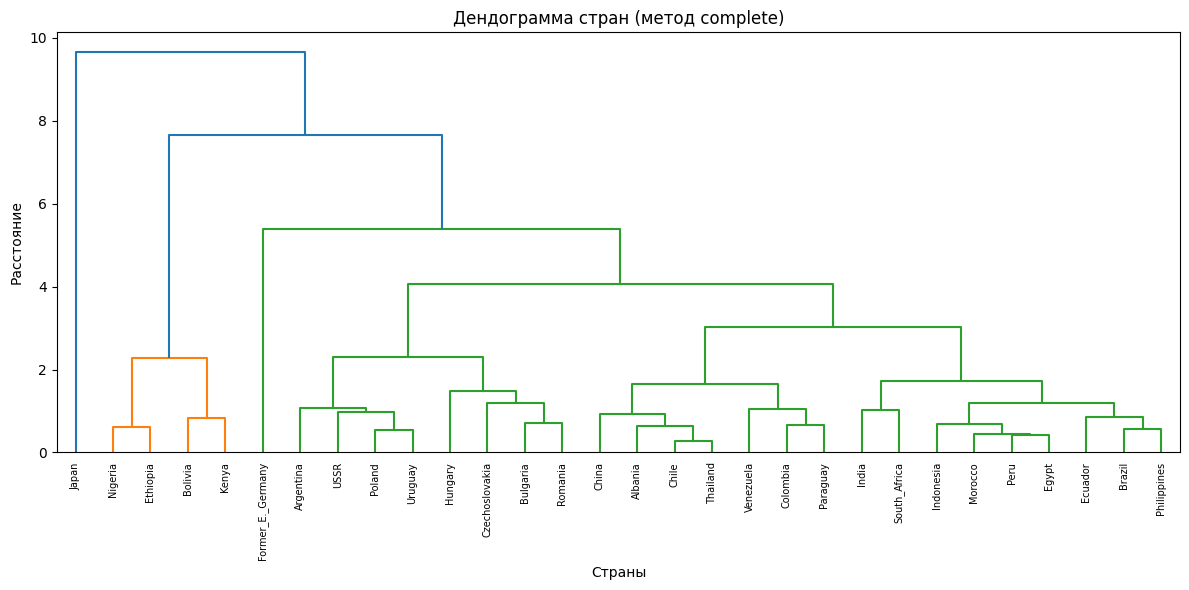

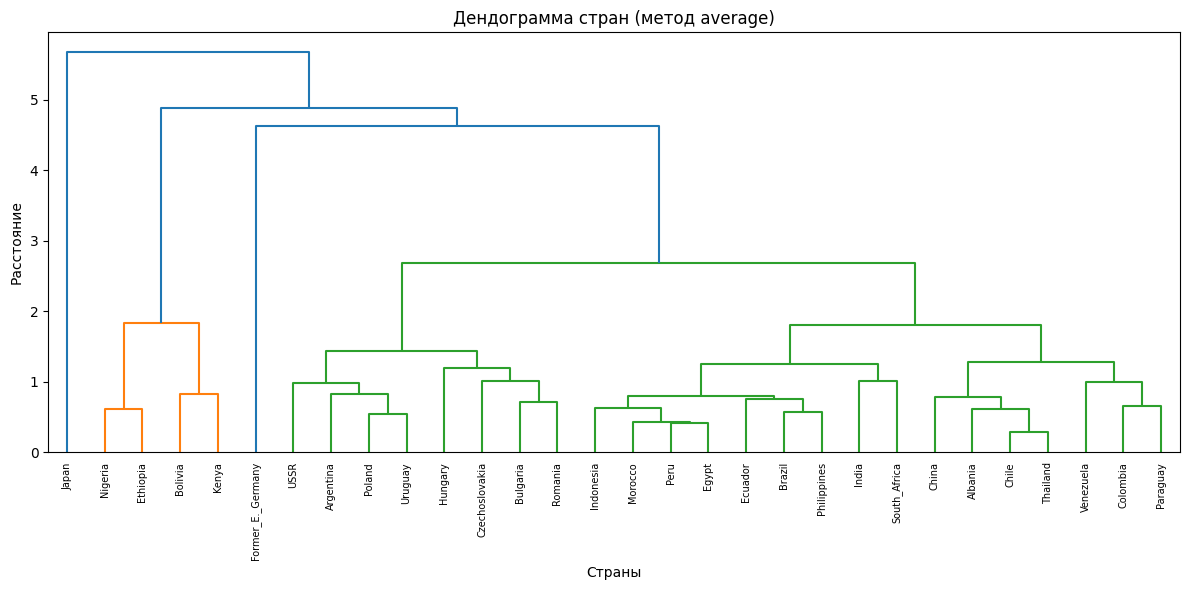

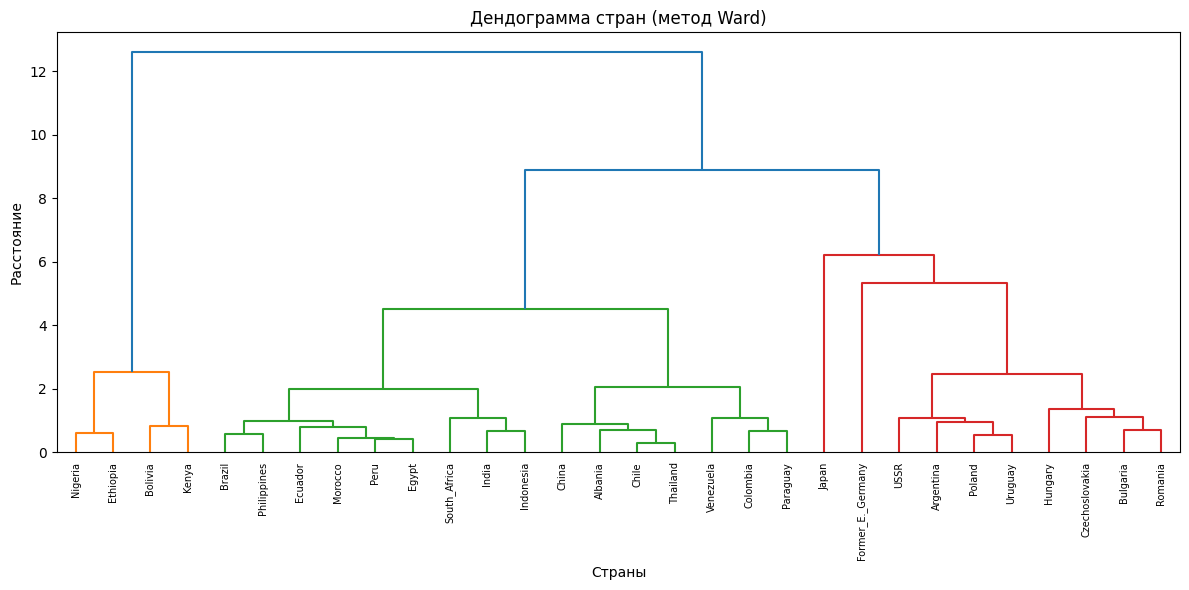

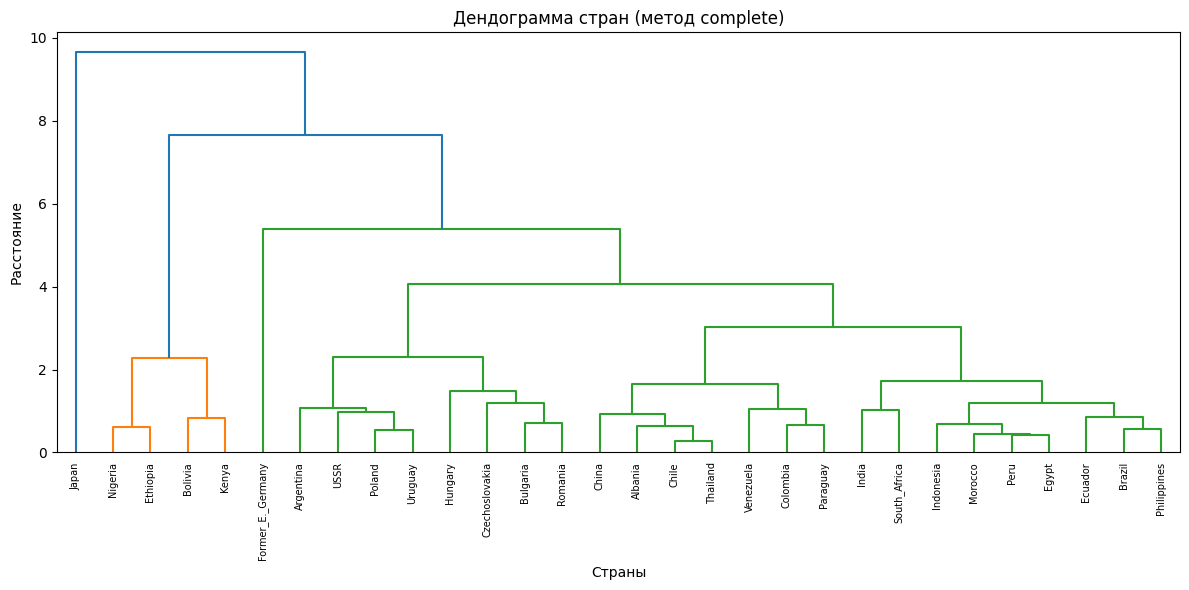

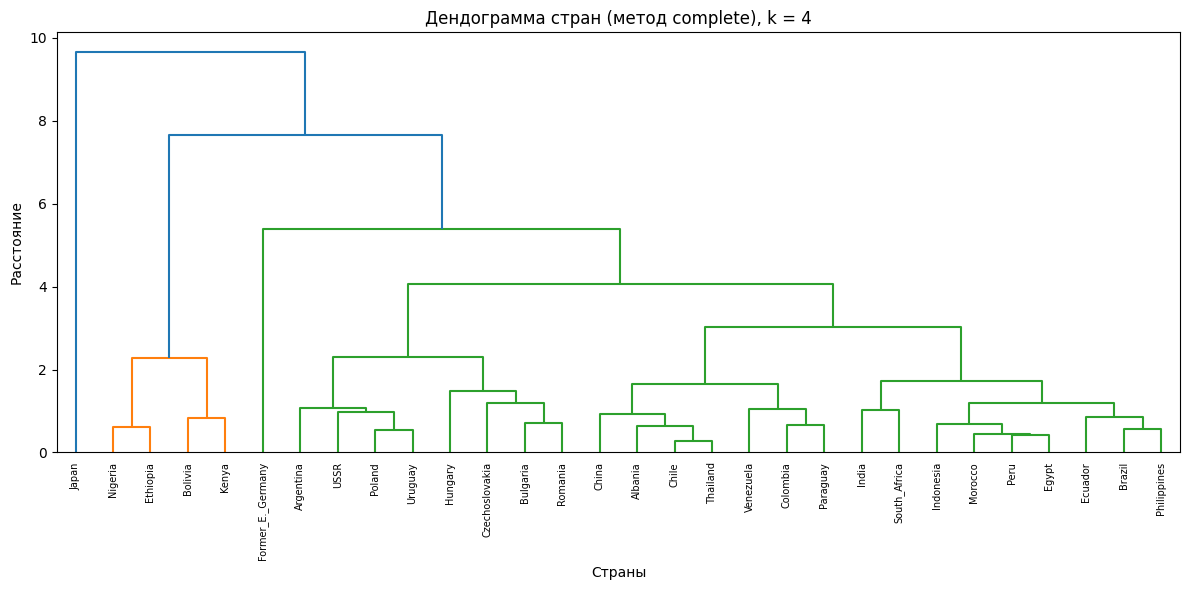

[('Albania', np.int32(2)),
 ('Bulgaria', np.int32(2)),
 ('Czechoslovakia', np.int32(2)),
 ('Former_E._Germany', np.int32(3)),
 ('Hungary', np.int32(2)),
 ('Poland', np.int32(2)),
 ('Romania', np.int32(2)),
 ('USSR', np.int32(2)),
 ('Argentina', np.int32(2)),
 ('Bolivia', np.int32(1))]

In [1]:
import pandas as pd
import numpy as np
import io

# ==========================================
# 1. ЗАГРУЗКА ДАННЫХ (Встроенный датасет для GitHub)
# ==========================================
# Данные встроены прямо в код, чтобы ноутбук работал на GitHub без внешних файлов.
csv_data = """страна;рождаем;смертн;деск_см;длит_муж;длит_жен;доход;регион
Albania;24.7;5.7;30.8;69.6;75.5;600;1
Bulgaria;12.5;11.9;14.4;68.3;74.7;2250;1
Czechoslovakia;13.4;11.7;11.3;71.8;77.7;2980;1
Former_E._Germany;12.0;12.4;7.6;69.8;75.9;-9999;1
Hungary;11.6;13.4;14.8;65.4;73.8;2780;1
Poland;15.0;9.7;15.4;68.5;76.5;3500;1
Romania;15.8;10.5;22.5;68.0;73.5;2100;1
USSR;18.0;9.5;24.0;65.0;74.0;4500;1
Argentina;25.0;8.5;18.0;68.0;75.0;3100;2
Bolivia;40.0;12.0;90.0;55.0;60.0;800;2
Brazil;30.0;7.0;60.0;65.0;71.0;2400;2
Chile;24.0;6.0;35.0;68.0;75.0;2200;2
Colombia;32.0;6.5;45.0;67.0;73.0;1900;2
Ecuador;38.0;7.5;55.0;66.0;71.0;1400;2
Paraguay;38.0;6.0;45.0;68.0;72.0;1300;2
Peru;35.0;8.0;65.0;65.0;69.0;1500;2
Uruguay;20.0;9.0;15.0;69.0;76.0;3400;2
Venezuela;35.0;5.5;30.0;68.0;74.0;3800;2
China;21.0;6.5;35.0;68.0;71.0;1200;3
India;30.0;9.0;70.0;62.0;64.0;900;3
Japan;10.0;7.0;5.0;76.0;82.0;15000;3
Thailand;25.0;6.0;40.0;68.0;74.0;1800;3
Egypt;35.0;8.0;60.0;64.0;67.0;1600;4
Kenya;45.0;12.0;80.0;58.0;61.0;1100;4
Nigeria;48.0;14.0;95.0;52.0;55.0;1000;4
South_Africa;32.0;10.0;55.0;62.0;67.0;2800;4
Indonesia;30.0;8.0;65.0;63.0;67.0;1500;5
Philippines;32.0;7.0;50.0;66.0;70.0;1400;5
Morocco;33.0;8.0;55.0;65.0;69.0;1700;6
Ethiopia;46.0;15.0;100.0;50.0;54.0;800;6"""

# Читаем данные прямо из строки (имитирует чтение CSV файла)
df = pd.read_csv(io.StringIO(csv_data), sep=';')

print("✅ Данные успешно загружены!")
print(df.head())

# Заменим код пропусков -9999 на NaN
df['доход'] = df['доход'].replace(['-9999', '-9 999'], np.nan)

# Очищаем числовые столбцы от пробелов и заменяем запятые на точки
num_cols = ['рождаем', 'смертн', 'деск_см', 'длит_муж', 'длит_жен']
for col in num_cols:
    df[col] = (
        df[col]
        .astype(str)
        .str.replace('\u00a0', ' ', regex=False)
        .str.replace(' ', '', regex=False)      
        .str.replace(',', '.', regex=False)     
    )

# Преобразуем все числовые столбцы в float
for col in num_cols + ['доход']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# 2. ВЫДЕЛЯЕМ ЧИСЛОВЫЕ ПРИЗНАКИ
X = df[num_cols + ['доход']].copy()
countries = df['страна']
region = df['регион']

# Удаляем строки с пропусками
mask = X.notnull().all(axis=1)
X = X[mask]
countries = countries[mask]
region = region[mask]

print(f"\n✅ Размер после очистки: {X.shape}")

# СТАНДАРТИЗАЦИЯ
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_st = scaler.fit_transform(X)   # X_st — numpy-массив стандарт. признаков

# 3. ПРОВЕРКА СКЛОННОСТИ К КЛАСТЕРИЗАЦИИ (Hopkins)
from sklearn.neighbors import NearestNeighbors
import random

def hopkins(X, sample_size=0.1):
    X = np.array(X)
    n, d = X.shape
    m = int(sample_size * n)

    nbrs = NearestNeighbors(n_neighbors=1).fit(X)

    # случайные точки в единичном гиперкубе
    rand_X = np.random.rand(m, d)
    u_dist, _ = nbrs.kneighbors(rand_X)

    # случайные реальные объекты
    rand_index = random.sample(range(0, n), m)
    w_dist, _ = nbrs.kneighbors(X[rand_index])

    H = u_dist.sum() / (u_dist.sum() + w_dist.sum())
    return H

H_stat = hopkins(X_st, sample_size=0.15)
H_stat

# 4. ОПРЕДЕЛЕНИЕ ЧИСЛА КЛАСТЕРОВ (метод локтя)
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

wss = []          # список для WSS (inertia_ в KMeans)
K = range(2, 10)  # будем проверять от 2 до 9 кластеров

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=123)
    kmeans.fit(X_st)             
    wss.append(kmeans.inertia_)  # inertia_ = суммарная внутрикластерная сумма квадратов

plt.figure(figsize=(8, 5))
plt.plot(K, wss, "o-")
plt.xlabel("Число кластеров k")
plt.ylabel("WSS (внутрикластерная сумма квадратов)")
plt.title("Метод локтя")
plt.grid(True)
plt.show()

# 5. КЛАСТЕРИЗАЦИЯ МЕТОДОМ k-MEANS (k = 4)
k = 4
kmeans = KMeans(n_clusters=k, random_state=123)
clusters = kmeans.fit_predict(X_st)

# добавим кластеры к странам
clustered = pd.DataFrame({
    "Страна": countries.values,
    "Кластер": clusters,
    "Регион": region.values
})
clustered.head()

# 6. СРАВНЕНИЕ КЛАСТЕРОВ С РЕГИОНАМИ
import pandas as pd
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# DataFrame с результатами кластеризации (мы его строили раньше)
# clustered: Страна, Кластер, Регион
print(clustered.head())

# 1) Контингентная таблица "Регион × Кластер"
ct = pd.crosstab(clustered["Регион"], clustered["Кластер"])
print("Таблица соответствия регионов и кластеров:")
print(ct)

# 2) Количественные меры сходства разбиений
# метка региона для тех же стран, что и в X_st
true_labels = clustered["Регион"].values
cluster_labels = clustered["Кластер"].values

ari = adjusted_rand_score(true_labels, cluster_labels)
nmi = normalized_mutual_info_score(true_labels, cluster_labels)

print(f"Adjusted Rand Index (ARI): {ari:.3f}")
print(f"Normalized Mutual Information (NMI): {nmi:.3f}")

# 7. Построение дендаграм
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

# Евклидова метрика + разные методы агломерации
Z_single   = linkage(X_st, method='single',   metric='euclidean')
Z_complete = linkage(X_st, method='complete', metric='euclidean')
Z_average  = linkage(X_st, method='average',  metric='euclidean')
Z_ward     = linkage(X_st, method='ward',     metric='euclidean')

def plot_dendro(Z, title, labels=None, k=None, color_threshold=None):
    plt.figure(figsize=(12, 6))
    dendrogram(
        Z,
        labels=labels,
        leaf_rotation=90,
        leaf_font_size=7,
        color_threshold=color_threshold
    )
    plt.title(title)
    plt.xlabel("Страны")
    plt.ylabel("Расстояние")
    plt.tight_layout()
    plt.show()

# 1) метод ближнего соседа (single)
plot_dendro(Z_single,   "Дендограмма стран (метод single)",   labels=countries.tolist())

# 2) метод полного связывания (complete)
plot_dendro(Z_complete, "Дендограмма стран (метод complete)", labels=countries.tolist())

# 3) метод средней связи (average)
plot_dendro(Z_average,  "Дендограмма стран (метод average)",  labels=countries.tolist())

# 4) метод Варда
plot_dendro(Z_ward,     "Дендограмма стран (метод Ward)",     labels=countries.tolist())


from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
import matplotlib.pyplot as plt
import numpy as np

# 8.1. Строим матрицы слияний 
Z_single   = linkage(X_st, method='single',   metric='euclidean')
Z_complete = linkage(X_st, method='complete', metric='euclidean')
Z_average  = linkage(X_st, method='average',  metric='euclidean')
Z_ward     = linkage(X_st, method='ward',     metric='euclidean')

# 2. Выбираем метод complete как основной
Z = Z_complete

# 3. Число кластеров
k = 4

# 4. Смотрим дендрограмму 
plt.figure(figsize=(12, 6))
dendrogram(
    Z,
    labels=countries.tolist(),
    leaf_rotation=90,
    leaf_font_size=7
)
plt.title("Дендограмма стран (метод complete)")
plt.xlabel("Страны")
plt.ylabel("Расстояние")
plt.tight_layout()
plt.show()

# 5. Находим порог высоты для раскраски ветвей (примерно для k=4)
last_merges = Z[-(k-1):, 2]         # высоты последних (k-1) слияний
threshold = last_merges.mean()      # берём среднее как порог

# 6. Дендрограмма с раскраской 4 кластеров
plt.figure(figsize=(12, 6))
dendrogram(
    Z,
    labels=countries.tolist(),
    leaf_rotation=90,
    leaf_font_size=7,
    color_threshold=threshold
)
plt.title("Дендограмма стран (метод complete), k = 4")
plt.xlabel("Страны")
plt.ylabel("Расстояние")
plt.tight_layout()
plt.show()

# 7. Если нужно получить номера кластеров:
clusters_hier = fcluster(Z, t=k, criterion='maxclust')
list(zip(countries[:10], clusters_hier[:10]))